# 05 · The polls themselves

Part 1 of the study plan (`docs/study_plan.md`): what the polls look like before comparing them with the results.
Built block by block: **coverage**, then trajectories, rank stability, pollsters and noise.

Input: `data/final/polls.csv` (notebook 04). Tables go to `results/tables/`, figures to `results/figures/`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from polls import metrics, timeline

pd.set_option("display.width", 200)
TABLES, FIGURES = ROOT / "results" / "tables", ROOT / "results" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

calendar = timeline.load(ROOT / "config" / "elections.yaml")
rows = timeline.add_time(pd.read_csv(ROOT / "data" / "final" / "polls.csv", low_memory=False), calendar)
ELECTIONS = sorted(rows["election"].unique())

## 1 · Coverage

One row per poll: when, by whom, how big, how many scenarios, and its ballot scenario if it has one.

In [2]:
tested = rows[rows["share_status"] != "not_tested"]
ballot = tested[tested["ballot_scenario"]]
polls = rows.drop_duplicates("poll_id")[["election", "poll_id", "institute", "institute_family", "sponsor", "date",
                                          "days_before", "weeks_before", "phase", "rolling", "sample_size"]].copy()
polls["n_scenarios"] = polls["poll_id"].map(rows.groupby("poll_id")["scenario_id"].nunique())
polls["has_ballot_scenario"] = polls["poll_id"].isin(ballot["poll_id"])
polls["n_candidates_ballot"] = polls["poll_id"].map(ballot.groupby("poll_id")["candidate"].nunique())
polls["rolling"] = polls["rolling"].fillna(False).astype(bool)

by_election = polls.groupby("election").agg(
    polls=("poll_id", "size"), pollsters=("institute_family", "nunique"),
    first_poll=("date", "min"), last_poll=("date", "max"),
    days_before_first=("days_before", "max"), days_before_last=("days_before", "min"),
    with_ballot_scenario=("has_ballot_scenario", "sum"), rolling=("rolling", "sum"),
    multi_scenario=("n_scenarios", lambda x: int((x > 1).sum())))
phases = pd.crosstab(polls["election"], polls["phase"])
coverage = by_election.join(phases)
coverage.to_csv(TABLES / "coverage_by_election.csv")
coverage

,polls,pollsters,first_poll,last_poll,days_before_first,days_before_last,with_ballot_scenario,rolling,multi_scenario,before the official list,official list to two weeks before,last two weeks
election,,,,,,,,,,,,
2002,98,6,1999-05-07,2002-04-18,1080,3,49,0,0,81,5,12
2007,107,6,2005-01-21,2007-04-20,821,2,107,0,1,69,20,18
2012,124,8,2007-11-02,2012-04-17,1633,5,116,0,19,95,17,12
2017,148,12,2012-10-12,2017-04-21,1654,2,109,0,66,103,23,22
2022,231,11,2017-10-18,2022-04-08,1635,2,184,32,76,161,37,33


### Polls per pollster

Pollster families (Sofres, TNS Sofres, Kantar → one family).

In [3]:
by_pollster = pd.crosstab(polls["institute_family"], polls["election"], margins=True, margins_name="all")
by_pollster = by_pollster.sort_values("all", ascending=False)
by_pollster.to_csv(TABLES / "coverage_by_pollster.csv")
by_pollster

election,2002,2007,2012,2017,2022,all
institute_family,,,,,,
all,98,107,124,148,231,708
Ifop,16,22,37,40,42,157
Ipsos,21,25,20,17,25,108
OpinionWay,0,0,15,13,51,79
Harris Interactive,0,0,12,11,44,67
BVA,10,11,12,20,13,66
Kantar (Sofres),23,17,6,11,4,61
CSA,23,20,13,2,0,58
Elabe,0,0,0,18,25,43


### Pace: polls per week before the vote

The last 52 weeks. Week 1 is the last seven days before the first round.

share of each election's polls in the last 4 and 8 weeks:


,4,8
election,,
2002,0.24,0.44
2007,0.30,0.55
2012,0.20,0.38
2017,0.26,0.43
2022,0.26,0.43


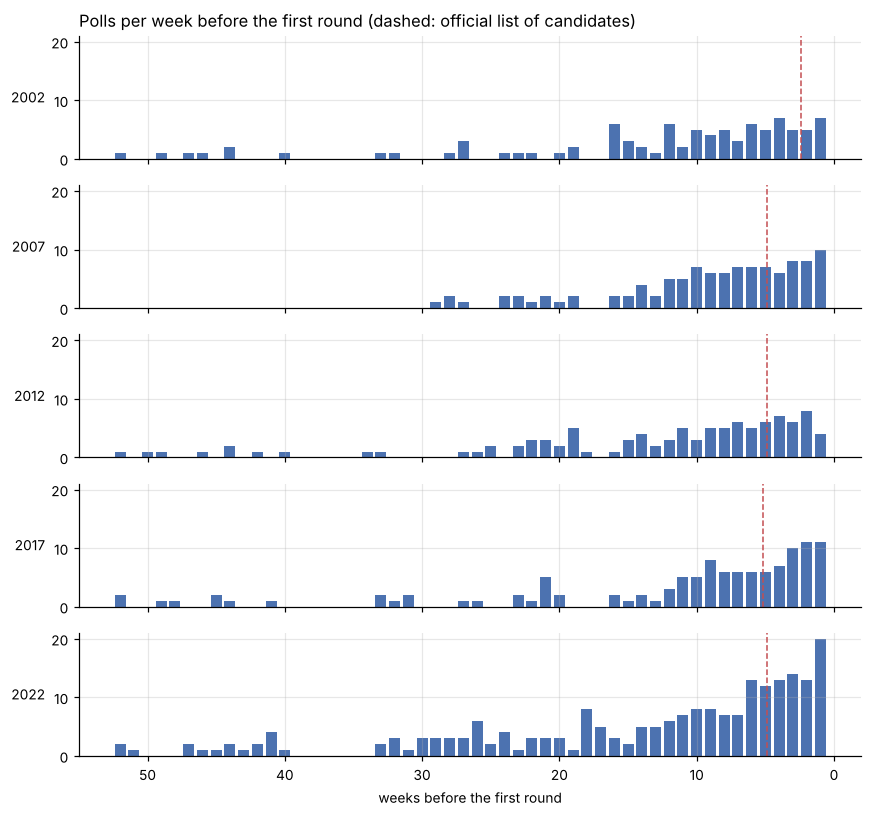

In [4]:
weekly = (polls[polls["weeks_before"] <= 52].groupby(["election", "weeks_before"]).size()
          .unstack("election").reindex(range(1, 53), fill_value=0).fillna(0).astype(int))
weekly.to_csv(TABLES / "coverage_polls_per_week.csv")

fig, axes = plt.subplots(len(ELECTIONS), 1, figsize=(8, 7.5), sharex=True, sharey=True)
for ax, e in zip(axes, ELECTIONS):
    ax.bar(weekly.index, weekly[e], width=0.8, color="#4c72b0")
    lst = (calendar.loc[e, "first_round"] - calendar.loc[e, "official_list"]).days / 7
    ax.axvline(lst, color="#c44e52", lw=1, ls="--")
    ax.set_ylabel(str(e), rotation=0, ha="right", va="center")
axes[0].set_title("Polls per week before the first round (dashed: official list of candidates)", loc="left")
axes[-1].set_xlabel("weeks before the first round")
axes[-1].invert_xaxis()
fig.tight_layout()
fig.savefig(FIGURES / "coverage_polls_per_week.png")
print("share of each election's polls in the last 4 and 8 weeks:")
pd.DataFrame({w: polls[polls["weeks_before"] <= w].groupby("election").size() / polls.groupby("election").size()
              for w in (4, 8)}).round(2)

### Sample sizes (2017 and 2022)

The base of respondents giving a voting intention, as Wikipedia gives it. Absent before 2017.

In [5]:
n = polls.dropna(subset=["sample_size"])
samples = n.groupby("election")["sample_size"].describe(percentiles=[0.1, 0.5, 0.9])[["count", "min", "10%", "50%", "90%", "max"]]
samples["rolling_median"] = n[n["rolling"]].groupby("election")["sample_size"].median()
samples["one_off_median"] = n[~n["rolling"]].groupby("election")["sample_size"].median()
samples.to_csv(TABLES / "coverage_sample_sizes.csv")
samples.round(0)

,count,min,10%,50%,90%,max,rolling_median,one_off_median
election,,,,,,,,
2017,147.0,586.0,926.0,1401.0,5696.0,21326.0,NaN,1401.0
2022,230.0,893.0,1005.0,1502.0,2600.0,16228.0,1578.0,1483.0


### Candidates tested in the ballot scenario

How many candidates a poll offers, against how many were on the ballot. In 2007 and 2012, Wikipedia leaves out
small candidates in many polls (see the spot check).

In [6]:
on_ballot = rows.groupby("election")["slot"].apply(lambda s: s.dropna().nunique())
cands = polls[polls["has_ballot_scenario"]].groupby(["election", "phase"], observed=True)["n_candidates_ballot"].median().unstack()
cands.insert(0, "on_ballot", on_ballot)
cands.to_csv(TABLES / "coverage_candidates_tested.csv")
cands

phase,on_ballot,before the official list,official list to two weeks before,last two weeks
election,,,,
2002,16,16.0,16.0,16.0
2007,12,11.0,12.0,12.0
2012,10,10.0,10.0,10.0
2017,11,9.0,11.0,11.0
2022,12,14.0,12.0,12.0
